In [100]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt


In [101]:
data = pd.read_csv('/Users/indranilray/Desktop/VEDAM/SEM 3/ML/class 7/CW/Titanic-Dataset.csv')
data.head()
# data.info()

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S


In [102]:
#preprocessing the data
columns_to_drop = ['PassengerId', 'Name', 'Ticket', 'Cabin', 'Embarked']

# data.drop(columns_to_drop)
data = data.drop(columns = columns_to_drop)
data.dropna(inplace=True)
data.info()

<class 'pandas.DataFrame'>
Index: 714 entries, 0 to 890
Data columns (total 7 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   Survived  714 non-null    int64  
 1   Pclass    714 non-null    int64  
 2   Sex       714 non-null    str    
 3   Age       714 non-null    float64
 4   SibSp     714 non-null    int64  
 5   Parch     714 non-null    int64  
 6   Fare      714 non-null    float64
dtypes: float64(2), int64(4), str(1)
memory usage: 44.6 KB


In [103]:
#feature scaling ( bringing values in range of 0 and 1 )
from sklearn.preprocessing import MinMaxScaler

numerical_Columns = ['Age', 'SibSp', 'Parch', 'Fare']
scaler = MinMaxScaler()

data[numerical_Columns] = scaler.fit_transform(data[numerical_Columns])

data.head()


,Survived,Pclass,Sex,Age,SibSp,Parch,Fare
0,0,3,male,0.271174,0.2,0.0,0.014151
1,1,1,female,0.472229,0.2,0.0,0.139136
2,1,3,female,0.321438,0.0,0.0,0.015469
3,1,1,female,0.434531,0.2,0.0,0.103644
4,0,3,male,0.434531,0.0,0.0,0.015713


In [104]:
#encode non-numerical data
from sklearn.preprocessing import LabelEncoder

label_encoder = LabelEncoder()

data['Sex'] = label_encoder.fit_transform(data['Sex'])
data.head()

,Survived,Pclass,Sex,Age,SibSp,Parch,Fare
0,0,3,1,0.271174,0.2,0.0,0.014151
1,1,1,0,0.472229,0.2,0.0,0.139136
2,1,3,0,0.321438,0.0,0.0,0.015469
3,1,1,0,0.434531,0.2,0.0,0.103644
4,0,3,1,0.434531,0.0,0.0,0.015713


In [ ]:
# train-test split
from sklearn.model_selection import train_test_split

X = data.drop('Survived', axis=1)
y = data['Survived']

X_train,X_test, y_train, y_test = train_test_split(X, y , test_size=0.2, random_state = 42)

In [106]:
# training he KNN model
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score

k = 5

knn = KNeighborsClassifier(n_neighbors=k)
knn.fit(X_train, y_train)

y_pred = knn.predict(X_test)

accuracy = accuracy_score(y_test, y_pred)
print(accuracy)

0.7692307692307693


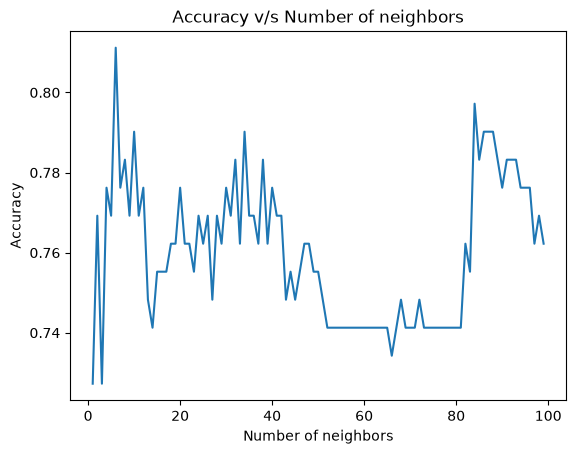

In [108]:
accuracy_scores = []
neighbors = np.arange(1,100)

for k in neighbors:

    knn = KNeighborsClassifier(n_neighbors=k)

    knn.fit(X_train, y_train)

    y_pred = knn.predict(X_test)

    accuracy = accuracy_score(y_test, y_pred)
    accuracy_scores.append(accuracy)

plt.plot(neighbors, accuracy_scores)
plt.xlabel("Number of neighbors")
plt.ylabel('Accuracy')
plt.title("Accuracy v/s Number of neighbors")
plt.show()


In [128]:
k = 8

knn = KNeighborsClassifier(n_neighbors=k)
knn.fit(X_train, y_train)
y_pred = knn.predict(X_test)

accuracy = accuracy_score(y_test, y_pred)
print(accuracy)


0.7832167832167832
